---
title: PACF and ACF
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg

## PACF (Partial AutoCorrelation Function)

In Lecture 19, we looked at the following heuristic procedure for selecting the AR order (i.e., selecting $p$ for fitting the AR($p$) model): 

Here is an approach that we can use to select the order $p$ in AR($p$). 

For each $p = 1, \ldots, p_{\max}$, we fit an AR($p$) model to the data. We record $\widehat{\phi}_{p,p}$, the estimated coefficient of the last lag in that model, together with its approximate 95% confidence interval. We then plot these estimates and intervals against $p$.

The idea is that if the data follow an AR($p_0$) model, additional lags beyond $p_0$ have zero coefficients. We therefore look for a cutoff after which the estimates fluctuate near zero, with most of their confidence intervals containing zero. The location of this cutoff suggests a suitable AR order.

This is a heuristic. We examine the entire plot rather than stopping at the first interval containing zero, because later coefficients may still be substantial. Conversely, an isolated interval excluding zero at a large lag may occur simply by chance when many orders are examined. The suggested order can be assessed further by checking residuals and comparing forecasting performance.

As an illustration, let us again use the sunspots dataset. 

        0     1    2  3  4
0  1700.5   8.3 -1.0 -1  1
1  1701.5  18.3 -1.0 -1  1
2  1702.5  26.7 -1.0 -1  1
3  1703.5  38.3 -1.0 -1  1
4  1704.5  60.0 -1.0 -1  1


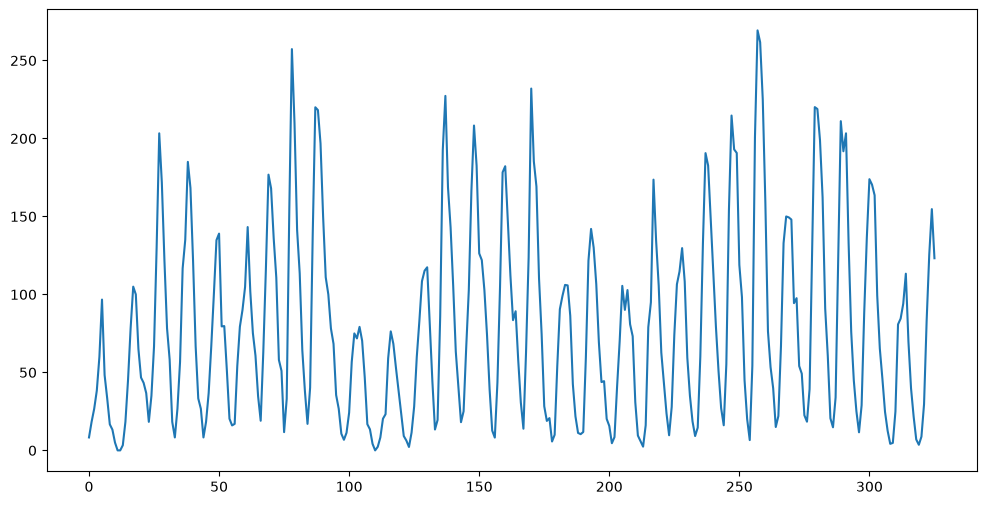

In [2]:
sunspots = pd.read_csv('SN_y_tot_V2.0_17Sept2026.csv', header = None, sep = ';')
print(sunspots.head())
y = sunspots.iloc[:,1].values
n = len(y)
plt.figure(figsize = (12, 6))
plt.plot(y)
plt.show()

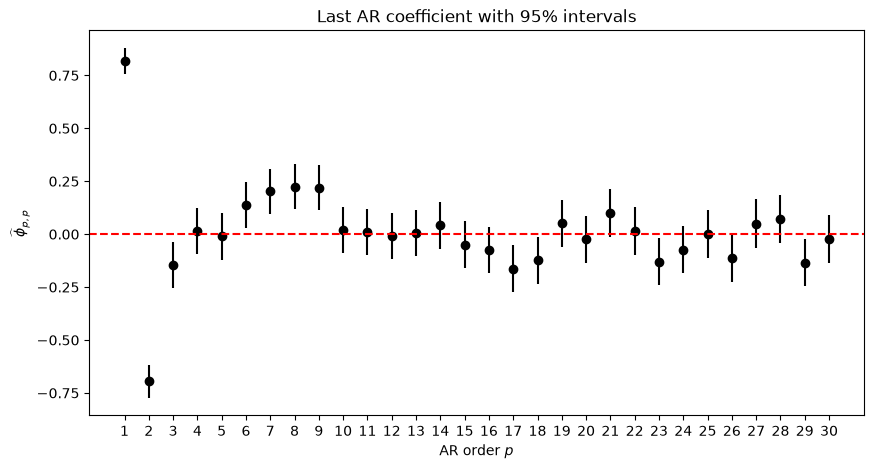

In [4]:
p_max = 30  # Choose the maximum AR order (this is somewhat arbitrary; choose a large enough value to see the pattern)
p_values = range(1, p_max + 1)
phi, ci = [], []

for p in p_values:
    fit = AutoReg(y, lags = p).fit()
    phi.append(fit.params[-1])
    ci.append(fit.conf_int()[-1])

ci = np.array(ci)

plt.figure(figsize=(10, 5))
plt.plot(p_values, phi, 'ko')
plt.vlines(p_values, ci[:, 0], ci[:, 1], color='black')
plt.axhline(0, color='red', linestyle='--')
plt.xticks(p_values)
plt.xlabel('AR order $p$')
plt.ylabel(r'$\widehat{\phi}_{p,p}$')
plt.title('Last AR coefficient with 95% intervals')
plt.show()

In the above plot, we are plotting both the fitted value for $\phi_p$ (when AR(p) is fit) as well as the corresponding 95\% confidence interval. We can get a simpler version of this plot by plotting only the fitted $\phi_p$ (and omitting the confidence intervals). 

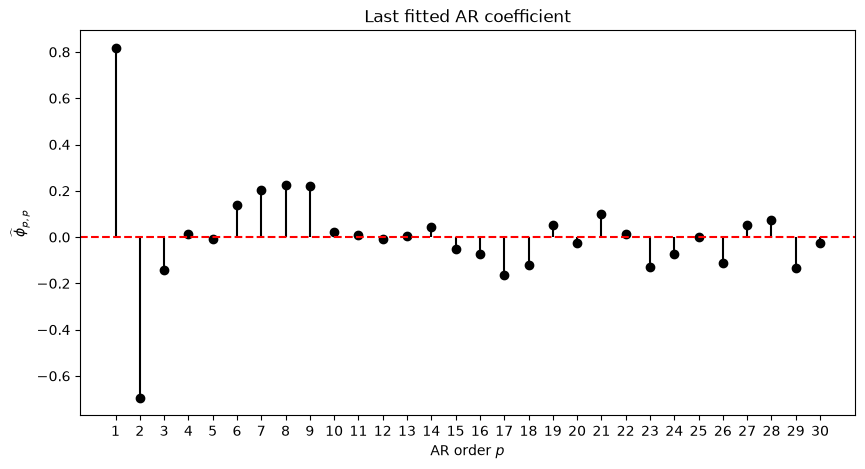

In [6]:
p_max = 30
p_values = range(1, p_max + 1)
phi = []

for p in p_values:
    fit = AutoReg(y, lags=p).fit()
    phi.append(fit.params[-1])

plt.figure(figsize=(10, 5))
plt.plot(p_values, phi, 'ko')
plt.vlines(p_values, 0, phi, color='black')
plt.axhline(0, color='red', linestyle='--')
plt.xticks(p_values)
plt.xlabel('AR order $p$')
plt.ylabel(r'$\widehat{\phi}_{p,p}$')
plt.title('Last fitted AR coefficient')
plt.show()

In the literature, the above plot is referred to as the sample PACF (Partial AutoCorrelation Function) plot of the data. There is an inbuilt function in statsmodels to compute this (pacf) and to plot this (plot_pacf). Here is how these functions work. 

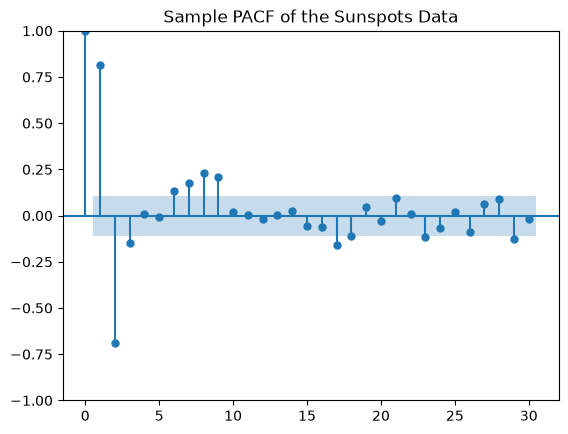

In [9]:
p_max = 30
from statsmodels.tsa.stattools import pacf
pacf_vals = pacf(y, nlags=p_max, method = 'ols') #these pacf values start with the value 1 at lag 0. 

from statsmodels.graphics.tsaplots import plot_pacf
plot_pacf(y, lags = p_max)
plt.title("Sample PACF of the Sunspots Data")
plt.show()

The PACF values (given by the functions pacf and plotted by plot_pacf) start with the value 1 at $p = 0$. In other words, the PACF value at $p = 0$ is always 1 (regardless of the data) so we ignore this value; and pay attention only to PACF for $p = 1, 2, \dots, p_{\max}$. 

Below we check if the PACF values outputted by the pacf function match exactly with our calculation of the coefficients $\phi_p$ when fitting AR($p$). 

In [10]:
print(np.column_stack([phi, pacf_vals[1:]])) 

[[ 0.81703769  0.81703769]
 [-0.69541909 -0.69541909]
 [-0.14446005 -0.14446005]
 [ 0.0137408   0.0137408 ]
 [-0.01016752 -0.01016752]
 [ 0.1384172   0.1384172 ]
 [ 0.2035669   0.2035669 ]
 [ 0.22328627  0.22328627]
 [ 0.21954062  0.21954062]
 [ 0.02056707  0.02056707]
 [ 0.01077726  0.01077726]
 [-0.00809312 -0.00809312]
 [ 0.00533023  0.00533023]
 [ 0.04167164  0.04167164]
 [-0.05026545 -0.05026545]
 [-0.07467993 -0.07467993]
 [-0.16296494 -0.16296494]
 [-0.12285519 -0.12285519]
 [ 0.0513226   0.0513226 ]
 [-0.02407729 -0.02407729]
 [ 0.09988241  0.09988241]
 [ 0.01448813  0.01448813]
 [-0.13093041 -0.13093041]
 [-0.07242642 -0.07242642]
 [ 0.00174815  0.00174815]
 [-0.11308473 -0.11308473]
 [ 0.05036624  0.05036624]
 [ 0.071989    0.071989  ]
 [-0.13397222 -0.13397222]
 [-0.02359065 -0.02359065]]


Both the values coincide exactly. This is actually a general fact. The sample PACF at 'lag' $p$ is actually defined as the fitted estimate of $\phi_p$ when the AR($p$) model is fit to the data. 

The natural question then is the following: Why is the estimate of $\phi_p$ when AR($p$) is fit to the data known as the partial autocorrelation at lag $p$? This is explained below. 

### Regression and Partial Correlation

Once again, the sample pacf at lag $p$ is defined as the estimate $\hat{\phi}_p$ of $\phi_p$ when the AR($p$) model is fit to the data. Why does this definition have the name "partial correlation"? In statistics, the partial correlation between two variables $y, x$ given a bunch of other variables $z_1, \dots, z_k$ is defined as the correlation between the residuals $e^{y \mid z_1, \dots, z_k}$ and $e^{x \mid z_1, \dots, z_k}$. Below we calculate the partial correlation in terms of residuals, and then see how it is related to our definition of the sample pacf. 

Let us first fix a value of $p$ and then compute the sample PACF at lag $p$ directly (without using inbuilt library functions). 

In [11]:
p = 9 #fix a value of p
yreg = y[p:] #these are the response values in the autoregression
Xmat = np.ones((n-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y[p-j : n-j].reshape(-1, 1)
    Xmat = np.column_stack([Xmat, col])
armod = sm.OLS(yreg, Xmat).fit()
print(armod.params)
pacf_lag_p = armod.params[-1]
print(pacf_lag_p)

[ 1.26279267e+01  1.17023433e+00 -4.19499656e-01 -1.36597826e-01
  1.03750543e-01 -6.69284094e-02  1.44401407e-03  1.57749176e-02
 -4.38532862e-02  2.19540620e-01]
0.2195406201858306


Here the response variable yreg denotes $y_t, t = p+1, \dots, n$. The first column of Xmat is the column of ones, the second column is $y_{t-1}, t = p+1, \dots, n$, third column is $y_{t-2}, t = p+1, \dots, n$ and so on with the last column being $y_{t-p}, t = p+1, \dots, n$. 

In [12]:
print(np.column_stack([yreg, Xmat]))
print(y)

[[ 13.3   1.   16.7 ...  26.7  18.3   8.3]
 [  5.    1.   13.3 ...  38.3  26.7  18.3]
 [  0.    1.    5.  ...  60.   38.3  26.7]
 ...
 [125.5   1.   83.2 ...  39.8  69.8 113.3]
 [154.7   1.  125.5 ...  21.7  39.8  69.8]
 [123.2   1.  154.7 ...   7.   21.7  39.8]]
[  8.3  18.3  26.7  38.3  60.   96.7  48.3  33.3  16.7  13.3   5.    0.
   0.    3.3  18.3  45.   78.3 105.  100.   65.   46.7  43.3  36.7  18.3
  35.   66.7 130.  203.3 171.7 121.7  78.3  58.3  18.3   8.3  26.7  56.7
 116.7 135.  185.  168.3 121.7  66.7  33.3  26.7   8.3  18.3  36.7  66.7
 100.  134.8 139.   79.5  79.7  51.2  20.3  16.   17.   54.   79.3  90.
 104.8 143.2 102.   75.2  60.7  34.8  19.   63.  116.3 176.8 168.  136.
 110.8  58.   51.   11.7  33.  154.2 257.3 209.8 141.3 113.5  64.2  38.
  17.   40.2 138.2 220.  218.2 196.8 149.8 111.  100.   78.2  68.3  35.5
  26.7  10.7   6.8  11.3  24.2  56.7  75.   71.8  79.2  70.3  46.8  16.8
  13.5   4.2   0.    2.3   8.3  20.3  23.2  59.   76.3  68.3  52.9  38.5
  24.2   9

Now let us calculate the same sample PACF value using partial correlation. Specifically, we will calculate the partial correlation between the variables $y_t$ and $y_{t-p}$ given all the intervening variables $y_{t-1}, y_{t-2}, \dots, y_{t-p+1}$. For this, we first need to calculate the residual of $y_t$ given $y_{t-1}, \dots, y_{t-p+1}$ as well as the residual of $y_{t-p}$ given $y_{t-1}, \dots, y_{t-p+1}$. 

The residual of $y_t$ given $y_{t-1}, \dots, y_{t-p+1}$ is calculated as follows. 

In [13]:
armod1 = sm.OLS(yreg, Xmat[:,:-1]).fit()
res_y = armod1.resid

The residual of $y_{t-p}$ given $y_{t-1}, \dots, y_{t-p+1}$ is calculated as follows. 

In [14]:
armod2 = sm.OLS(Xmat[:,-1], Xmat[:,:-1]).fit()
res_x = armod2.resid

The sample correlation between these two residuals is the sample PACF at lag $p$: 

In [15]:
pcorr = np.corrcoef(res_y, res_x)[0, 1]
print(pcorr, pacf_lag_p)

0.22133128716736616 0.2195406201858306


Note that this is basically the same as the Sample PACF at lag $p$. The minor discrepancy occurs because the two residuals do not have exactly the same variance. More precisely, the regression coefficient $\hat{\beta}_j$ in a multiple linear regression of $y$ on a set of covariates $x_1, \dots, x_k$ satisfies the following formula: 
\begin{equation*}
  \hat{\beta}_j = \text{corr}(e^{y \mid x_k, k \neq j}, e^{x_j \mid x_k, k \neq j}) \sqrt{\frac{\text{var}(e^{y \mid x_k, k \neq j})}{\text{var}(e^{x_j \mid x_k, k \neq j})}}
\end{equation*}

In [16]:
var_res_y = np.var(res_y)
var_res_x = np.var(res_x)
print(var_res_y, var_res_x)

570.0746123783798 579.4120815077788


These residual variances are similar but not exactly the same. This explains why the correlation between the residuals does not exactly equal the fitted regression coefficient $\hat{\phi}_p$. But if we multiply the partial correlation by the ratio of the standard deviations, we recover the sample pacf at lag p (i.e., $\hat{\phi}_p$) exactly. 

In [17]:
reg_coeff = pcorr * np.sqrt(var_res_y/var_res_x)
print(reg_coeff, pacf_lag_p)

0.21954062018583118 0.2195406201858306


The PACF is a standard diagnostic that is used to determine the order for a suitable AR model. 

## ACF (AutoCorrelation Function)

ACF is a standard diagnostic that is used to determine the order for a suitable MA model. Recall the definition of the MA($q$) model. Given a positive integer $q \geq
1$, the Moving Average model with order $q$ (denoted by MA($q$)) is
defined by the equation:
\begin{equation*}
  y_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2
  \epsilon_{t-2} + \dots + \theta_q \epsilon_{t-q}
\end{equation*}
where $\epsilon_t \overset{\text{i.i.d}}{\sim} N(0, \sigma^2)$. The
MA($q$) model has $q + 2$ unknown parameters which are estimated from
observed data: $\mu, \theta_1, \dots, \theta_q, \sigma$.

For the MA($q$) model, the correlation between $y_t$ and $y_{t+h}$ is given by: 
$$
\begin{align*}
 \text{cov}(y_t, y_{t+h}) = \left\{
  \begin{array}{lr}
    \frac{\sum_{j=0}^{q-h} \theta_j \theta_{j+h}}{\sum_{j=0}^q
    \theta_j^2} & : 0 \leq h \leq q\\ 
    0 & : h > q
  \end{array}
\right.
\end{align*}
$$
The key here is to note that the correlation between $y_t$ and $y_{t+h}$ equals zero when $h > q$. This suggests using the following heuristic method to determine $q$. Calculate the sample autocorrelations for each lag $h$. The sample autocorrelation at lag $h$ is given by
\begin{align*}
  r_h := \frac{\sum_{t=1}^{n-h} (y_t - \bar{y})(y_{t+h} - 
  \bar{y})}{\sum_{t=1}^{n} (y_t -
  \bar{y})^2} ~~\text{for $h = 0, 1, 2, \dots$}
\end{align*}
Note that $r_0$ is always equal to 1.

The sample ACF $r_h, h \geq 0$ can be computed for any time series
dataset, although it is only useful for data for which stationary
models are appropriate.

If the sample ACF $r_h$ for a particular dataset becomes small (not exactly zero because of 
randomness) when $h$ exceeds a particular $q$, then MA($q$) is
probably a good model for that dataset. This diagnostic is very
commonly used when working with MA models.

It is a common diagnostic tool to look at both the ACF and PACF for a given dataset. By eyeballing them, once can find a suitable AR($p$) or a suitable MA($q$) model for the data. Below, we look at the ACF and PACF for the sunspots dataset. 

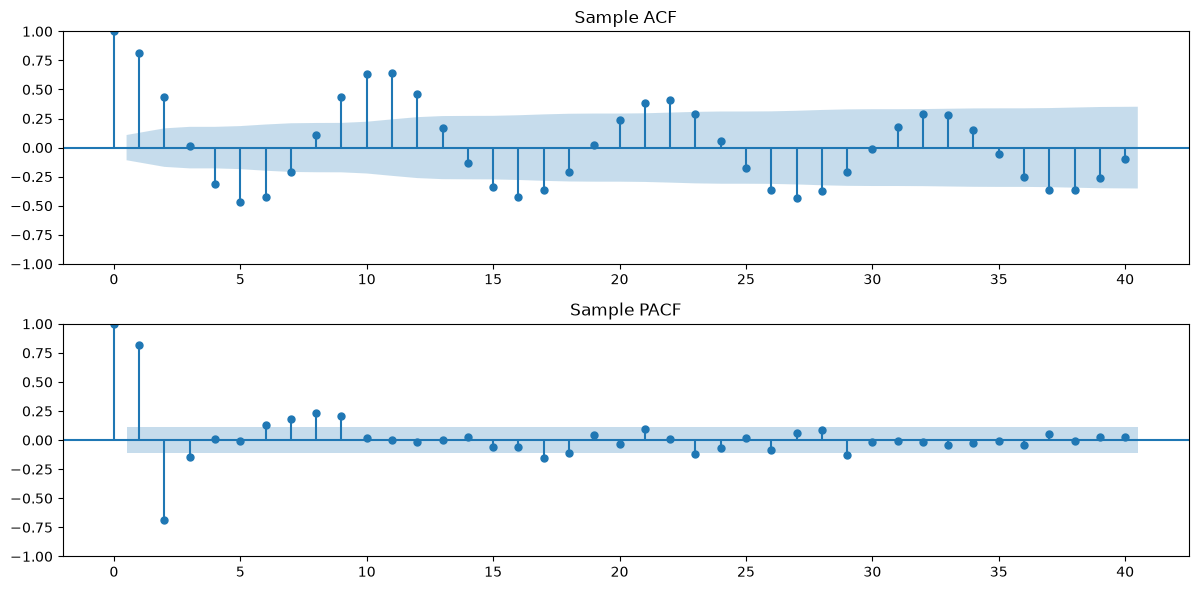

In [19]:
from statsmodels.graphics.tsaplots import plot_acf
h_max = 40
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 6))
plot_acf(y, lags = h_max, ax = axes[0])
axes[0].set_title("Sample ACF")
plot_pacf(y, lags = h_max, ax = axes[1])
axes[1].set_title("Sample PACF")
plt.tight_layout()
plt.show()

For this dataset, the ACF does not seem to have a simple structure in favor of an MA model. On the other hand, the PACF has two clear spikes at lags 1 and 2 suggesting AR(2). One can also go for the AR(9) model to take into account the spikes at lags 7, 8, 9. Below we fit both these models and obtain predictions. 

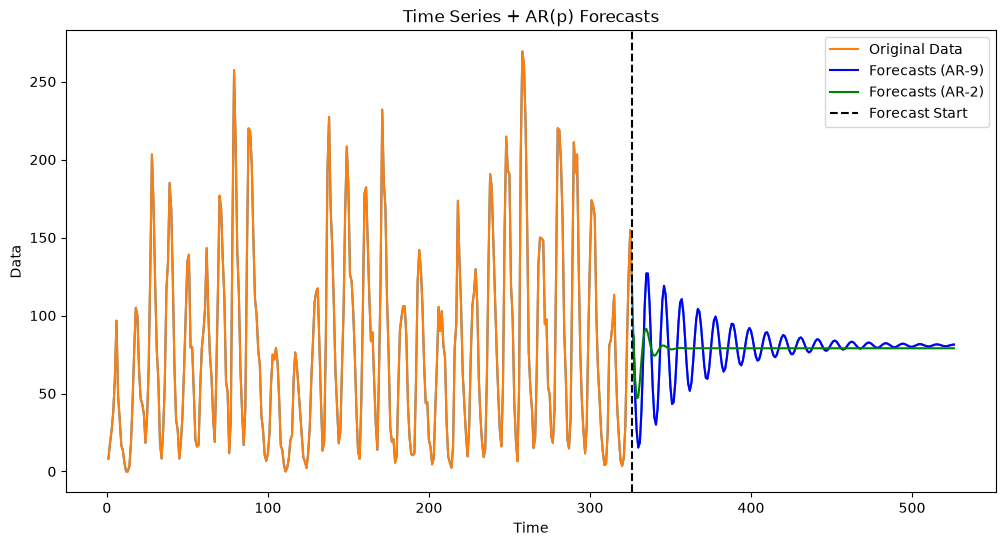

In [20]:
armd_2 = AutoReg(y, lags = 2).fit() 
armd_9 = AutoReg(y, lags = 9).fit() 

k = 200
fcast_9 = armd_9.get_prediction(start = n, end = n+k-1)
fcast_mean_9 = fcast_9.predicted_mean

fcast_2 = armd_2.get_prediction(start = n, end = n+k-1)
fcast_mean_2 = fcast_2.predicted_mean

yhat_9 = np.concatenate([y, fcast_mean_9])
yhat_2 = np.concatenate([y, fcast_mean_2])

plt.figure(figsize=(12, 6))
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat_9, color='C0')
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), fcast_mean_9, label='Forecasts (AR-9)', color='blue')
plt.plot(range(n + 1, n + k + 1), fcast_mean_2, label='Forecasts (AR-2)', color='green')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

Visually the AR(9) predictions appear better at least for the initial few predictions. 

## AutoReg vs ARIMA

There are two inbuilt functions in statsmodels for fitting AR models: (a) AutoReg (which we used previously), and (b) ARIMA (which can be used more generally for all ARIMA models). We compare and contrast these two ways below. We use the GNP dataset (from FRED). 

  observation_date      GNP
0       1947-01-01  244.142
1       1947-04-01  247.063
2       1947-07-01  250.716
3       1947-10-01  260.981
4       1948-01-01  267.133


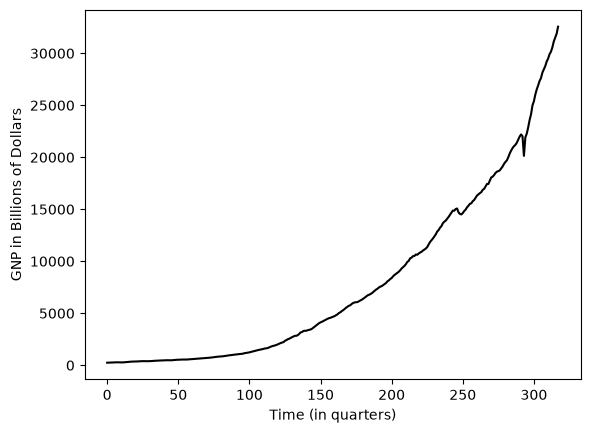

In [22]:
gnp = pd.read_csv("GNP_05Nov2026.csv")
#this is quarterly data
print(gnp.head())

y = gnp['GNP'].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Time (in quarters)')
plt.ylabel('GNP in Billions of Dollars')
plt.show()

Instead of the raw GNP, we work with their logarithms as usual. 

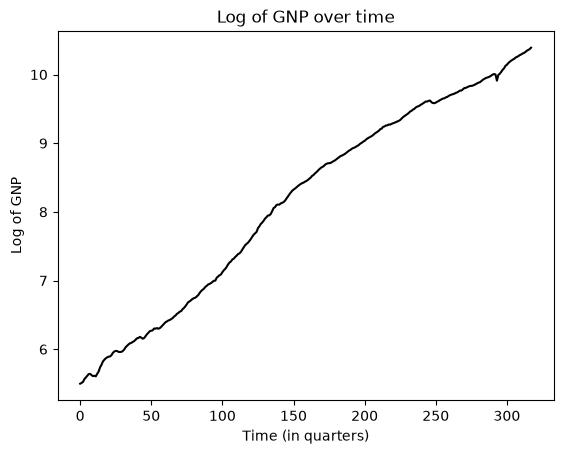

In [23]:
ylog = np.log(y)
plt.plot(ylog, color = 'black')
plt.title('Log of GNP over time')
plt.xlabel('Time (in quarters)')
plt.ylabel('Log of GNP')
plt.show()

We fit AR models to differences of the logs (after multiplying by 100). The data now becomes percent change in GNP. 

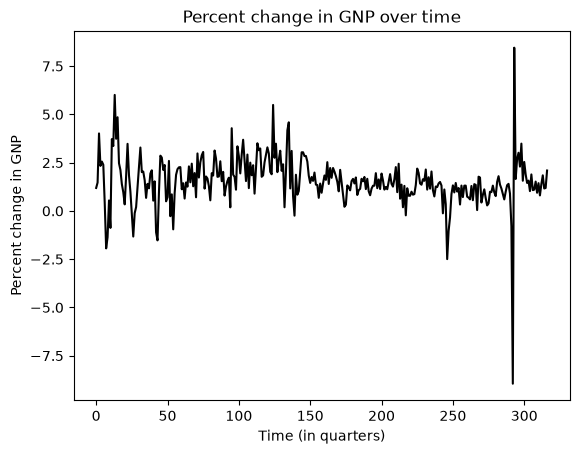

In [24]:
ylogdiff = 100 * np.diff(ylog)
plt.plot(ylogdiff, color = 'black')
plt.title('Percent change in GNP over time')
plt.xlabel('Time (in quarters)')
plt.ylabel('Percent change in GNP')
plt.show()

Let us now fit the AR(1) model to this dataset. Let us first fit it using AutoReg. 

In [25]:
md_autoreg = AutoReg(ylogdiff, lags = 1).fit()
print(md_autoreg.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  317
Model:                     AutoReg(1)   Log Likelihood                -516.768
Method:               Conditional MLE   S.D. of innovations              1.242
Date:                Sun, 08 Nov 2026   AIC                           1039.536
Time:                        14:06:18   BIC                           1050.803
Sample:                             1   HQIC                          1044.037
                                  317                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1627      0.109     10.640      0.000       0.949       1.377
y.L1           0.2477      0.055      4.544      0.000       0.141       0.355
                                    Roots           

AutoReg uses the method of conditional MLE, which maximizes the conditional likelihood of $y_2, \dots, y_n$ given $y_1$. This conditional likelihood is given by: 
\begin{equation*}
\left(\frac{1}{\sqrt{2 \pi} \sigma}
    \right)^{n-1} \exp \left(-\frac{1}{2 \sigma^2} \sum_{t=2}^n (y_t -
    \phi_0 - \phi_1 y_{t-1})^2 \right). 
\end{equation*}    


In [26]:
#the estimates of $\phi_0$ and $\phi_1$ are given by: 
print(md_autoreg.params)
#if you want the estimate of sigma^2, do the following: 
print(md_autoreg.sigma2)

[1.16274269 0.24771615]
1.5415767673398826


Next we use the ARIMA function to fit AR(1). ARIMA models have a triplet of indices $(p, d, q)$. $p$ stands for the AR order, $d$ stands for the amount of differencing, and $q$ stands for the MA order. To fit AR(1) through the ARIMA function, we need to use $p = 1$, $d = 0$ and $q = 0$. 

In [28]:
from statsmodels.tsa.arima.model import ARIMA
md_arima = ARIMA(ylogdiff, order = (1,0,0)).fit()
print(md_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  317
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -517.973
Date:                Sun, 08 Nov 2026   AIC                           1041.945
Time:                        14:07:18   BIC                           1053.222
Sample:                             0   HQIC                          1046.450
                                - 317                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5437      0.112     13.783      0.000       1.324       1.763
ar.L1          0.2470      0.020     12.587      0.000       0.209       0.285
sigma2         1.5371      0.040     38.100      0.0

ARIMA parametrizes the AR(1) model differently from AutoReg. It writes the AR(1) model as: 
\begin{align*}
    y_t - \mu = \phi_1 (y_{t-1} - \mu) + \epsilon_t. 
\end{align*}
In other words, there is no $\phi_0$ parameter. It is replaced by $\mu - \mu \phi_1$. This means that $\phi_0 = \mu - \mu \phi_1$ or $\mu = \phi_0/(1 - \phi_1)$. So to compare the parameter estimates given by AutoReg and ARIMA, we need to convert the estimates $\phi_0, \phi_1$  from AutoReg to $\mu, \phi_1$. 

In [29]:
pars_autoreg = [md_autoreg.params[0]/(1 - md_autoreg.params[1]), md_autoreg.params[1], md_autoreg.sigma2]
pars_arima = md_arima.params
print(np.column_stack([pars_autoreg, pars_arima]))

[[1.54561697 1.54372907]
 [0.24771615 0.24699388]
 [1.54157677 1.53707575]]


The parameter estimates are similar but not exactly the same. This is because ARIMA is using a different method of parameter estimation compared to AutoReg. ARIMA works with the full likelihood of $y_1, \dots, y_n$ (not the conditional likelihood of $y_2, \dots, y_n$ given $y_1$). We saw in lecture 17 that the full likelihood for AR(1) is given by: 
\begin{equation*}
\frac{\sqrt{1 - \phi_1^2}}{\sqrt{2 \pi}
      \sigma} \exp \left(-\frac{1 - \phi_1^2}{2 \sigma^2} \left(y_1 -
        \frac{\phi_0}{1 - \phi_1} \right)^2 \right) \left(\frac{1}{\sqrt{2 \pi} \sigma}
    \right)^{n-1} \exp \left(-\frac{1}{2 \sigma^2} \sum_{t=2}^n (y_t -
    \phi_0 - \phi_1 y_{t-1})^2 \right). 
\end{equation*}    
Instead of parametrizing using $\phi_0, \phi_1$ and $\sigma$, an alternative parametrization is via $\phi_1, \sigma$ and $\mu := \phi_0/(1 - \phi_1)$. With this the likelihood becomes:
\begin{equation*}
\frac{\sqrt{1 - \phi_1^2}}{\sqrt{2 \pi}
      \sigma} \exp \left(-\frac{1 - \phi_1^2}{2 \sigma^2} \left(y_1 - \mu \right)^2 \right) \left(\frac{1}{\sqrt{2 \pi} \sigma}
    \right)^{n-1} \exp \left(-\frac{1}{2 \sigma^2} \sum_{t=2}^n ((y_t - \mu)
     - \phi_1 (y_{t-1} - \mu))^2 \right). 
\end{equation*}    


The following function computes the log-likelihood given values of the parameters.

In [30]:
def loglik_ar1(dt, pars):
    n = len(dt)
    mu = pars[0]
    phi1 = pars[1]
    sigma2 = pars[2]
    sigma = np.sqrt(sigma2)
    # First term: density of y1 under stationary AR(1)
    ll_start = 0.5 * np.log(1 - phi1**2) - 0.5*np.log(2*np.pi) - np.log(sigma) \
               - (1 - phi1**2) * (dt[0] - mu)**2 / (2*sigma2)
    # Second term: density of y2,...,yn
    residuals = (dt[1:] - mu) - phi1*(dt[:-1] - mu)
    ssr = np.sum(residuals**2)
    ll_rest = -(n-1)*0.5*np.log(2*np.pi) - (n-1)*np.log(sigma) - ssr/(2*sigma2)
    return ll_start + ll_rest

We can attempt to maximize this full log-likelihood using an inbuilt optimization function, starting with the parameter estimates given by AutoReg. The code for doing this is given below. This gives almost the same results as the parameter estimates given by ARIMA. 

In [31]:
from scipy.optimize import minimize
def neg_loglik_ar1(pars, dt):
    return -loglik_ar1(dt, pars)
init_pars = pars_autoreg
bounds = [(-np.inf, np.inf), (-0.99, 0.99), (1e-6, np.inf)] #note that the bound on phi1 ensures stationarity
res = minimize(neg_loglik_ar1, init_pars, args=(ylogdiff,), bounds=bounds)
print("MLE estimates from custom optimization:")
print(np.column_stack([pars_autoreg, pars_arima, res.x]))
print(loglik_ar1(ylogdiff, pars_autoreg), loglik_ar1(ylogdiff, pars_arima), loglik_ar1(ylogdiff, res.x))
#check that pars_arima and res.x are very close to each other (and they give the same log-likelihood)

MLE estimates from custom optimization:
[[1.54561697 1.54372907 1.54375572]
 [0.24771615 0.24699388 0.24699483]
 [1.54157677 1.53707575 1.53708839]]
-517.9735374533072 -517.9725743205034 -517.9725742723975


Another difference between AutoReg and ARIMA is that ARIMA, by default, only searches for parameters in the stable region but AutoReg does not place any such restrictions. Stable region corresponds to the values of the parameters for which the roots of the polynomial $1 - \phi_1 z - \phi_2 z^2 - \dots - \phi_p z^p$ are strictly larger than 1 in modulus. Another name for the stable region is 'causal-stationary' region (or simply 'stationary' region). For AR(1), the stable region corresponds to $|\phi_1| < 1$ (because the AR(1) polynomial is $1 - \phi_1 z$ whose root is $1/\phi_1$. So root having modulus strictly larger than 1 is equivalent to $|\phi_1| < 1$). 

To illustrate this difference between AutoReg and ARIMA, let us fit the AR(1) model to the original data (without any differencing and logging). Then the AutoReg will give an estimate of $\phi_1$ that is strictly larger than 1. But ARIMA will still give an estimate from the stable region (strictly smaller than 1 in absolute value). 

In [34]:
#Below we fit these models to the original data without any differencing or logging.
md_autoreg_y = AutoReg(y, lags = 1).fit()
print(md_autoreg_y.params[1])
#AutoReg's estimate of phi1 is slightly more than 1
md_arima_y = ARIMA(y, order = (1, 0, 0)).fit()
print(md_arima_y.params[1])
#ARIMA's estimate is less than 1 (even though quite close to 1)
#Also ARIMA gives an error/warning that initial parameters that is is using are out of the stationary region. 


1.0121954720762598
0.9999195196243736


/Users/aditya/mambaforge/envs/stat153fall2026/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


If we want the ARIMA function to not focus only on the stable region, then we have to explicitly use the clause 'enforce_stationarity = False'. 

In [35]:
md_arima_y_nostable = ARIMA(y, order = (1, 0, 0), enforce_stationarity = False).fit()
print(md_arima_y_nostable.params[1])

1.012079994049166


Let us now get back to fitting models for the logarithms for $y$. Instead of applying the ARIMA function to ylogdiff, we can apply it directly to ylog. In this case, we have to choose $d = 1$ (as opposed to $d = 0$). 

In [36]:
md_ylog = ARIMA(ylog*100, order = (1, 1, 0)).fit() #note that now d = 1
print(md_ylog.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  318
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -566.939
Date:                Sun, 08 Nov 2026   AIC                           1137.877
Time:                        14:37:05   BIC                           1145.395
Sample:                             0   HQIC                          1140.880
                                - 318                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6924      0.030     23.317      0.000       0.634       0.751
sigma2         2.0896      0.076     27.320      0.000       1.940       2.239
Ljung-Box (L1) (Q):                  62.72   Jarque-

The difference now is that the $\mu$ parameter is no longer present. In other words, the model that is fit here is: 
\begin{align*}
   100 \left( \log y_t - \log y_{t-1} \right) = \phi_1 100 \left( \log y_{t-1} - \log y_{t-2} \right) + \epsilon_t. 
\end{align*}
Whenever the differencing order is 1 or more, ARIMA does not use the intercept parameter. This makes a noticeable difference in predictions however. 

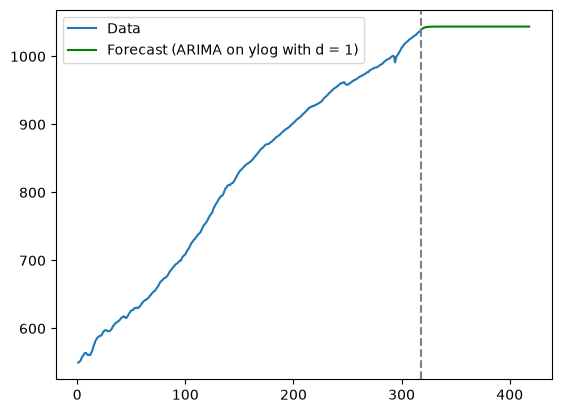

In [37]:
k = 100
n = len(ylog)
tme = range(1, n+1)
tme_future = range(n+1, n+k+1)

fcast = md_ylog.get_prediction(start = n, end = n+k-1) 
fcast_mean = fcast.predicted_mean #this gives the point predictions
plt.plot(tme, ylog*100, label = 'Data')
plt.plot(tme_future, fcast_mean, label = 'Forecast (ARIMA on ylog with d = 1)', color = 'green')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

On the other hand, if we use the model on ylogdiff, then the predictions for ylog are computed in the following way. We basically obtain predictions for the differenced series, and then use the predictions for $y_{n+1} - y_n, y_{n+2} - y_{n+1}, \dots, y_{n+k}-y_{n+k-1}$ to get predictions for $y_{n+1}, \dots, y_{n+k}$. This is done by taking telescoping sums of $y_{n+1} - y_n, y_{n+2} - y_{n+1}, \dots, y_{n+k}-y_{n+k-1}$, and then adding $y_n$. 

In [38]:
n = len(y)
k = 100
fcast_diff_1 = md_arima.get_prediction(start = n-1, end = n+k-2).predicted_mean #these are the forecasts for the differenced data
last_observed_ylog = 100*ylog[-1]
fcast_1 = np.zeros(k)
fcast_1[0] = last_observed_ylog + fcast_diff_1[0]
for i in range(1, k):
    fcast_1[i] = fcast_1[i-1] + fcast_diff_1[i]

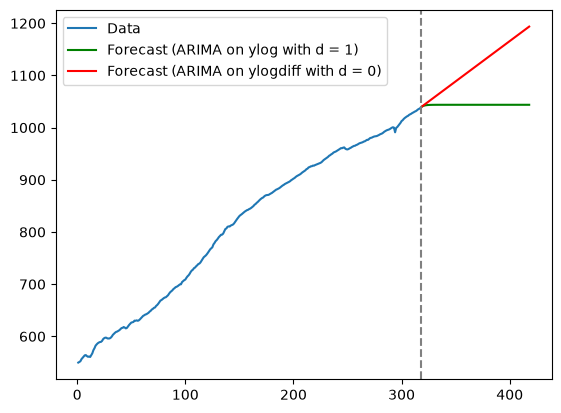

In [39]:
plt.plot(tme, ylog*100, label = 'Data')
plt.plot(tme_future, fcast_mean, label = 'Forecast (ARIMA on ylog with d = 1)', color = 'green')
plt.plot(tme_future, fcast_1, label = 'Forecast (ARIMA on ylogdiff with d = 0)', color = 'red')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

So here the presence of the intercept is leading to more intuitive predictions. 

## Another dataset from FRED

Here is a FRED dataset on total construction spending in the United States (https://fred.stlouisfed.org/series/TTLCONS). 

  observation_date  TTLCONS
0       1993-01-01   458080
1       1993-02-01   462967
2       1993-03-01   458399
3       1993-04-01   469425
4       1993-05-01   468998
405


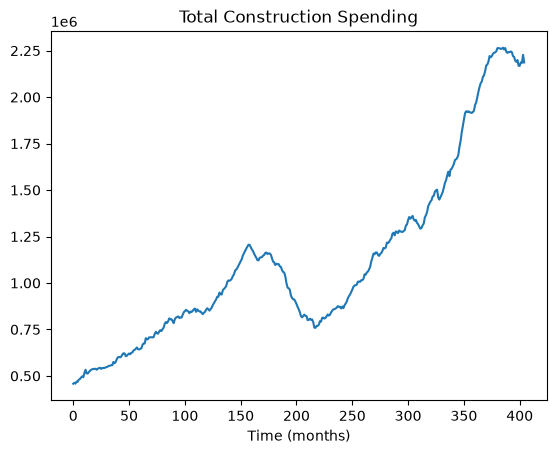

In [40]:
ttlcons = pd.read_csv('TTLCONS_05Nov2026.csv')
print(ttlcons.head())
y = ttlcons['TTLCONS'].to_numpy()
print(len(y))
plt.plot(y)
plt.title('Total Construction Spending')
plt.xlabel('Time (months)')
plt.show()

As usual, we fit models to logarithms of the data. 

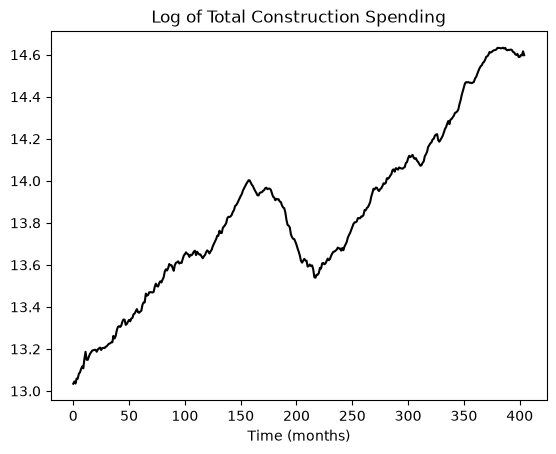

In [41]:
ylog = np.log(y)
plt.plot(ylog, color = 'black')
plt.title('Log of Total Construction Spending')
plt.xlabel('Time (months)')
plt.show()  

In order to obtain candidate models, let us first difference the data, and then look at acf and pacf. 

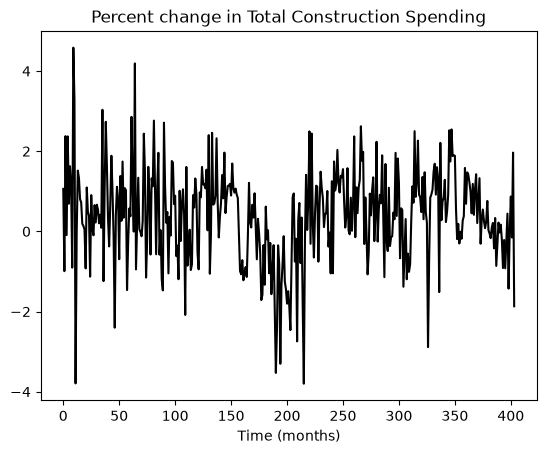

In [42]:
ylogdiff = 100 * np.diff(ylog)
plt.plot(ylogdiff, color = 'black')
plt.title('Percent change in Total Construction Spending')
plt.xlabel('Time (months)')
plt.show()

Here is how to compute the ACF and PACF.

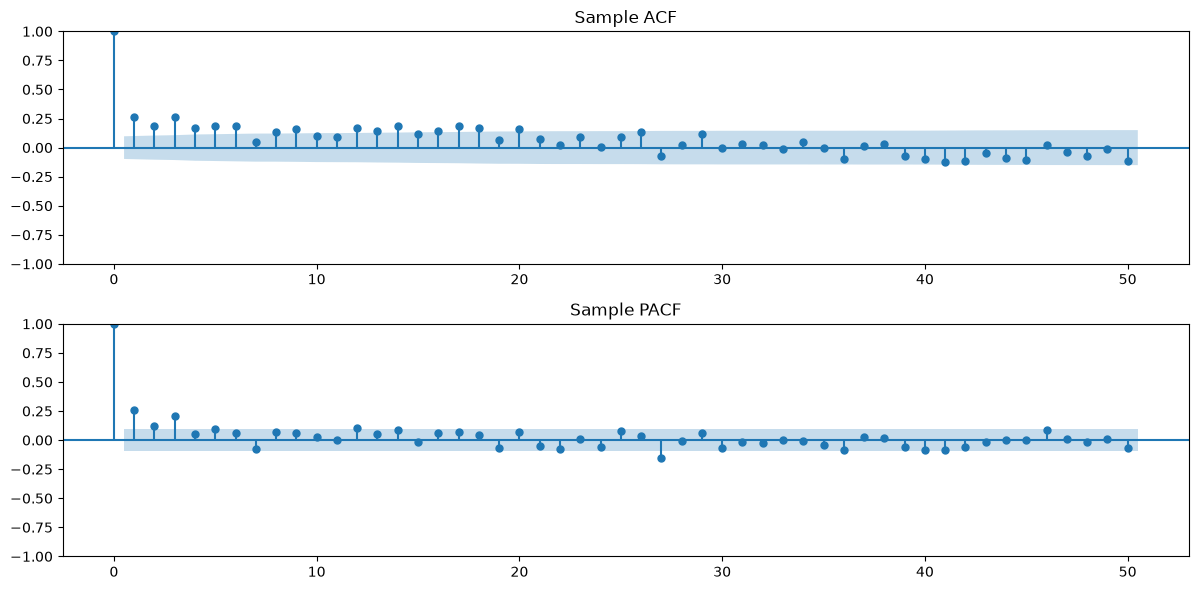

In [43]:
h_max = 50
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 6))
plot_acf(ylogdiff, lags = h_max, ax = axes[0])
axes[0].set_title("Sample ACF")
plot_pacf(ylogdiff, lags = h_max, ax = axes[1])
axes[1].set_title("Sample PACF")
plt.tight_layout()
plt.show()

These plots suggest: 
1. AR(3) for the differenced log data (to account for the three spikes in PACF)
2. MA(6) for the differenced log data (to account for the six spikes in ACF)
3. ARIMA(3, 1, 0) for the log data (this is technically the same as Model 1 but the ARIMA function does not include intercepts while fitting this model so it can lead to different predictions)
4. ARIMA(0, 1, 6) for the log data

We can also take another difference of the data, and then look at acf and pacf. 

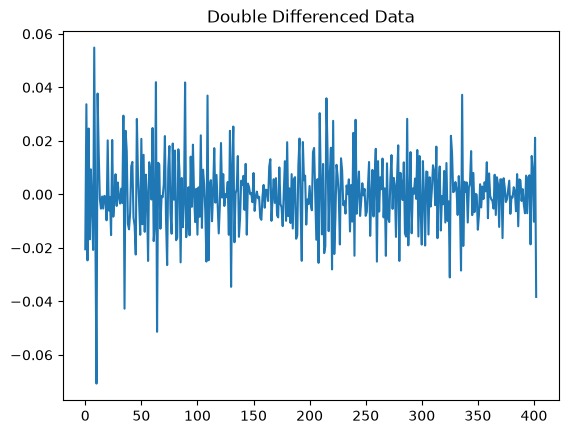

In [44]:
ylogdiff2 = np.diff(np.diff(ylog))
plt.plot(ylogdiff2)
plt.title("Double Differenced Data")
plt.show()

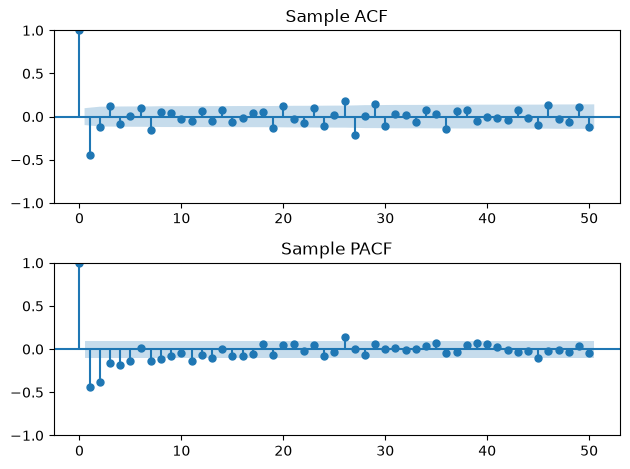

In [45]:
h_max = 50
fig, axes = plt.subplots(nrows = 2, ncols = 1)
plot_acf(ylogdiff2, lags = h_max, ax = axes[0])
axes[0].set_title("Sample ACF")
plot_pacf(ylogdiff2, lags = h_max, ax = axes[1])
axes[1].set_title("Sample PACF")
plt.tight_layout()
plt.show()

The ACF plot above (which has a single spike) suggests the ARIMA(0, 1, 2) model for ylog. 

Here is how to calculate the predictions for each of the five models. 

In [46]:
k = 100
n = len(ylog)
tme = range(1, n+1)
tme_future = range(n+1, n+k+1)

First is Model One: AR(3) for the differenced log data. 

In [47]:
#Model One: AR(3) for the differenced log data
md1 = ARIMA(ylogdiff, order = (3, 0, 0)).fit()
fcast_diff_1 = (md1.get_prediction(start = n-1, end = n+k-2).predicted_mean)/100 #these are the forecasts for the differenced data
last_observed_ylog = ylog[-1]
fcast_1 = np.zeros(k)
fcast_1[0] = last_observed_ylog + fcast_diff_1[0]
for i in range(1, k):
    fcast_1[i] = fcast_1[i-1] + fcast_diff_1[i]

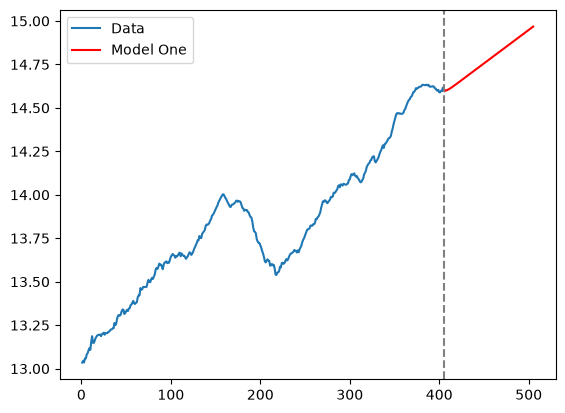

In [48]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

Next is Model Two: MA(6) on differenced log data. 

In [49]:
#Model Two: MA(6) for the differenced log data
md2 = ARIMA(ylogdiff, order = (0, 0, 6)).fit()
fcast_diff_2 = (md2.get_prediction(start = n-1, end = n+k-2).predicted_mean)/100 #these are the forecasts for the differenced data
last_observed_ylog = ylog[-1]
fcast_2 = np.zeros(k)
fcast_2[0] = last_observed_ylog + fcast_diff_2[0]
for i in range(1, k):
    fcast_2[i] = fcast_2[i-1] + fcast_diff_2[i]

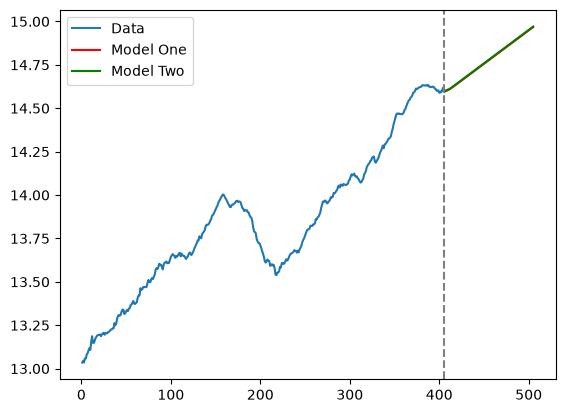

In [50]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.plot(tme_future, fcast_2, label = 'Model Two', color = 'green')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

So Model One and Model Two lead to basically the same predictions. 

Next is Model Three which ARIMA(3, 1, 0). 

In [55]:
#Model Three: ARIMA(3, 1, 0) for the log data
md3 = ARIMA(ylog, order = (3, 1, 0)).fit()
fcast_3 = md3.get_prediction(start = n, end = n+k-1).predicted_mean

/Users/aditya/mambaforge/envs/stat153fall2026/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


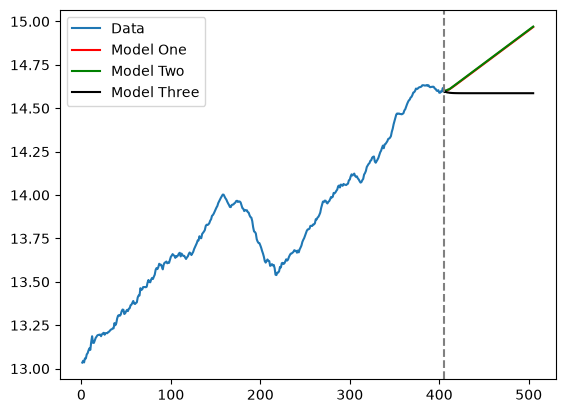

In [56]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.plot(tme_future, fcast_2, label = 'Model Two', color = 'green')
plt.plot(tme_future, fcast_3, label = 'Model Three', color = 'black')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

The prediction is flat because of the lack of the intercept term in ARIMA(3, 1, 0). 

In [57]:
#Model Four: ARIMA(0, 1, 6) for the log data
md4 = ARIMA(ylog, order = (0, 1, 6)).fit()
fcast_4 = md4.get_prediction(start = n, end = n+k-1).predicted_mean

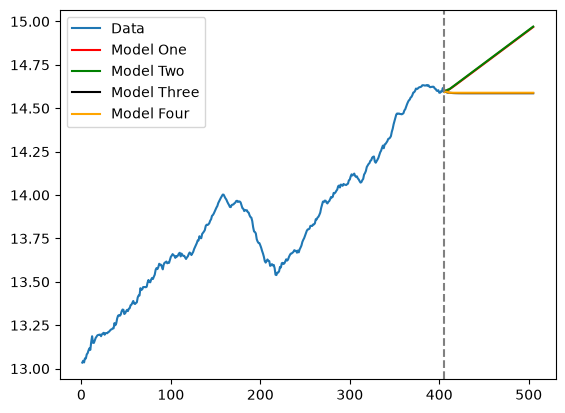

In [58]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.plot(tme_future, fcast_2, label = 'Model Two', color = 'green')
plt.plot(tme_future, fcast_3, label = 'Model Three', color = 'black')
plt.plot(tme_future, fcast_4, label = 'Model Four', color = 'orange')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

The forecasts for models 3 and 4 are largely similar. 

Finally below are the predictions for model 5. 

In [59]:
#Model Five: ARIMA(0, 2, 1) for the log data
md5 = ARIMA(ylog, order = (0, 2, 1)).fit()
fcast_5 = md5.get_prediction(start = n, end = n+k-1).predicted_mean

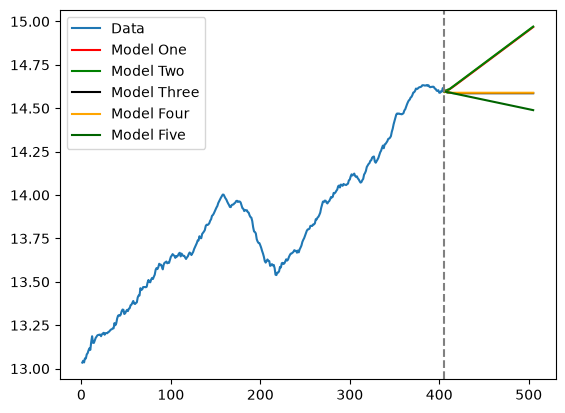

In [60]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.plot(tme_future, fcast_2, label = 'Model Two', color = 'green')
plt.plot(tme_future, fcast_3, label = 'Model Three', color = 'black')
plt.plot(tme_future, fcast_4, label = 'Model Four', color = 'orange')
plt.plot(tme_future, fcast_5, label = 'Model Five', color = 'darkgreen')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

Let us try to manually fit the AR(1) model to the double differenced data (so the model will involve an intercept), and then manually convert the predictions on the double differenced data to predictions on the original data. 

In [61]:
md6 = ARIMA(ylogdiff2, order = (0, 0, 1)).fit()
fcast_diff_6 = md6.get_prediction(start = n-2, end = n+k-3).predicted_mean


In [62]:
tmp1 = ylog[-1] - ylog[-2]
fcast_d1 = np.zeros(k)
fcast_d1[0] = tmp1 + fcast_diff_6[0]
for i in range(1, k):
    fcast_d1[i] = fcast_d1[i-1] + fcast_diff_6[i]

In [63]:
tmp2 = ylog[-1]
fcast_6 = np.zeros(k)
fcast_6[0] = tmp2 + fcast_d1[0]
for i in range(1, k):
    fcast_6[i] = fcast_6[i-1] + fcast_d1[i]

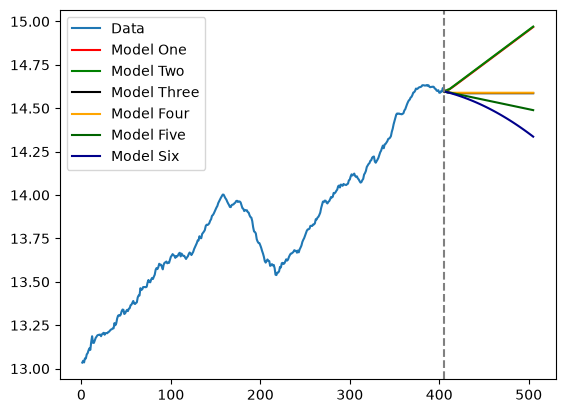

In [64]:
plt.plot(tme, ylog, label = 'Data')
plt.plot(tme_future, fcast_1, label = 'Model One', color = 'red')
plt.plot(tme_future, fcast_2, label = 'Model Two', color = 'green')
plt.plot(tme_future, fcast_3, label = 'Model Three', color = 'black')
plt.plot(tme_future, fcast_4, label = 'Model Four', color = 'orange')
plt.plot(tme_future, fcast_5, label = 'Model Five', color = 'darkgreen')
plt.plot(tme_future, fcast_6, label = 'Model Six', color = 'darkblue')
plt.axvline(x=n, color='gray', linestyle='--')
plt.legend()
plt.show()

All these models give quite different predictions. Which prediction do you like?